In [1]:
%load_ext autoreload
%autoreload 2

import torch
import json
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from einops import rearrange

import finsler_learning.shepplogan_pipeline as sp
from finsler_learning.shepplogan_pipeline.shepplogan_utils import *
from finsler_learning.shepplogan_pipeline import *
from finsler_learning.utils import *

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from finsler_learning.shepplogan_pipeline.shepplogan_utils import *
from finsler_learning.shepplogan_pipeline.shepplogan_image_regressor import (
    get_vae_shepplogan_dataloaders,
)

from finsler_learning.base_extrapolation import (
    ExtrapolationEvalRiemannConfig,
    ExtrapolationEvalFinslerConfig,
    extrapolation_evaluation,
)
from finsler_learning.base_quality_evaluation import evaluate_extrapolated_framework
from finsler_learning.shepplogan_pipeline.shepplogan_interpolation import (
    get_model_regressor_trained,
    get_randers_metric_trained,
)
from finsler_learning.base_extrapolation import *

from geodesic_toolbox.utils import (
    sample_cometric_normal,
    sample_cone_VMF,
)

In [3]:
def load_samples_geodesics(
    method_key: str, randers: bool, subset_idx: torch.Tensor = None
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads the precomputed geodesic trajectories and their corresponding Kendall tau values for a given method and Randers setting.

    Parameters:
    method_key : str
        The key representing the method used for geodesic computation.
    randers : bool
        Whether the Randers metric was used in the computation.

    Returns:
    z_traj : Tensor (B, T, latent_dim)
        The latent representations along the geodesic trajectories.
    x_hat : Tensor (B, T, C, H, W)
        The decoded images along the geodesic trajectories.
    t_traj : Tensor (B, T)
        The time points along the geodesic trajectories.
    kendall_tau : Tensor (B,)
        The Kendall tau values for each trajectory.
    """
    folder_name = f"geodesic_evaluation_{method_key}" + f"{'_randers' if randers else ''}"
    z_traj = torch.load(
        config.export_path / folder_name / "latent_geodesics_test.pth", map_location="cpu"
    )
    t_traj = torch.load(
        config.export_path / folder_name / "geo_t_pred_test.pth", map_location="cpu"
    )
    kendall_tau = torch.load(
        config.export_path / folder_name / "geo_kendall_tau_list_test.pth", map_location="cpu"
    )[0]

    if subset_idx is not None:
        z_traj = z_traj[subset_idx]
        t_traj = t_traj[subset_idx]
        kendall_tau = kendall_tau[subset_idx]

    x_hat = decode_traj(z_traj, model.decoder, config.device).cpu()
    return z_traj, x_hat, t_traj, kendall_tau


def load_samples_extrapolation(
    method_key: str, randers: bool, subset_idx: torch.Tensor = None
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads the precomputed geodesic trajectories and their corresponding Kendall tau values for a given method and Randers setting.

    Parameters:
    method_key : str
        The key representing the method used for geodesic computation.
    randers : bool
        Whether the Randers metric was used in the computation.

    Returns:
    x_hat : Tensor (B, T, C, H, W)
        The decoded images along the geodesic trajectories.
    t_traj : Tensor (B, T)
        The time points along the geodesic trajectories.
    kendall_tau : Tensor (B,)
        The Kendall tau values for each trajectory.
    """
    folder_name = f"extrapolation_evaluation_{method_key}" + f"{'_randers' if randers else ''}"
    z_traj = torch.load(
        config.export_path / folder_name / "extrapolated_traj_test.pth", map_location="cpu"
    )
    t_traj = torch.load(
        config.export_path / folder_name / "extrapolated_time_test.pth", map_location="cpu"
    )
    kendall_tau = torch.load(
        config.export_path / folder_name / "extrapolation_kendall_tau_test.pth",
        map_location="cpu",
    )

    if subset_idx is not None:
        z_traj = z_traj[subset_idx]
        t_traj = t_traj[subset_idx]
        kendall_tau = kendall_tau[subset_idx]

    x_hat = decode_traj(z_traj, model.decoder, config.device).cpu()
    return x_hat, t_traj, kendall_tau

In [4]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11")
with open(base_path / "shepplogan_pipeline_config.json", "r") as f:
    config = json.load(f)

config = SheppLoganPipelineConfig(**config)
config.export_path = Path(config.export_path)
config.device = torch.device(config.device)

latent_dim = config.latent_dim
export_path = config.export_path
device = config.device
batch_size = config.b_size_evaluation
alpha = config.alpha
ema_moment = config.ema_moment
eta = config.eta
n_pts = config.n_pts
k = config.n_neighbors
omega_strength = config.omega_strength
use_dummy_accuracy = config.use_dummy_accuracy
config

SheppLoganPipelineConfig(n_epochs_regressor=500, b_size_regressor=128, lr_regressor=5e-05, wd_regressor=1e-05, n_epochs_vae=1000, b_size_vae=128, lr_vae=5e-05, wd_vae=0.0, beta=1.0, lbda=1.0, lpip_weight=0.0, n_neighbors=16, margin=0, n_epochs_randers=50, b_size_randers=128, use_dummy_accuracy=False, lr_randers=0.01, wd_randers=1e-06, omega_strength=0.9, b_size_evaluation=32, eta=0.999, alpha=5.0, ema_moment=0.9, n_pts=25, skip_regressor=True, skip_vae=True, skip_randers=True, eval_interpolation=False, eval_extrapolation=True, export_path=PosixPath('/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11'), latent_dim=64, label_noise=0.0, K_cometric=None, IMG_SIZE=256, device=device(type='cuda'), eval_quality_interpolation=False, eval_quality_extrapolation=True, eval_regressor=False, no_symmetric=False, no_randers=False)

In [5]:
model = get_models(latent_dim=latent_dim)
dtype = next(model.parameters()).dtype
try_load_pretrained_models(export_path, model)
model = model.to(device)
model.eval()

regressor = get_model_regressor_trained(
    export_path=export_path,
    device=device,
).to(dtype)

dl_config = DatasetConfig(
    batch_size=batch_size,
)
shepp_logan_trainloader, shepp_logan_test_loader = get_shepplogan_dataloaders(
    dataset_config=dl_config,
    export_path=export_path,
)

shepp_logan_trainloader_vae, _ = get_vae_shepplogan_dataloaders(
    dataset_config=dl_config,
    latent_dim=latent_dim,
    device=device,
    export_path=export_path,
)

LOGGER.info(f"Number of training samples: {len(shepp_logan_trainloader.dataset)}")
LOGGER.info(f"Number of test samples: {len(shepp_logan_test_loader.dataset)}")

encoder = model.encoder.to(device)
decoder = model.decoder.to(device)
encoder.eval()
decoder.eval()

common_params = {
    "latent_dim": latent_dim,
    "dataloader_train": shepp_logan_trainloader,
    "dataloader_test": shepp_logan_test_loader,
    "encoder": encoder,
    "decoder": decoder,
    "regressor": regressor,
    "device": device,
    "reference_dataloader_train": shepp_logan_trainloader_vae,
    "T": n_pts,
}

100%|██████████| 500/500 [00:00<00:00, 505.32it/s]


In [6]:
methods = [
    ("Euclidean", "euclidean"),
    # ("LAND", "land"),
    # ("LAND RBF", "land_rbf"),
    # ("CovCentroids", "cov_centroids"),
    # ("PBCentroids", "pullback_centroids"),
    # ("RBF PB", "rbf_pullback"),
    # ("PBIG", "pbig"),
    # ("WarpedPB", "warped_pullback"),
    # ("Wasserstein", "wasserstein"),
    # ("HyperSpherical", "spherical")
]

In [7]:
cometric_type = "euclidean"
cometric = get_cometric(
    latent_dim=latent_dim,
    export_path=export_path,
    k=k,
    batch_size=batch_size,
    cometric_type=cometric_type,
    device=device,
).to(dtype)
randers_metric = get_randers_metric_trained(
    latent_dim=latent_dim,
    cometric=cometric,
    export_path=export_path,
    # beta=omega_strength,
    beta=0.9,
    use_dummy_accuracy=use_dummy_accuracy,
    device=device,
    cometric_type=cometric_type,
).to(dtype)

In [8]:
config_finsler = ExtrapolationEvalFinslerConfig(
    export_path=export_path / f"extrapolation_evaluation_{cometric_type}_randers",
    cometric=cometric,
    randers_metric=randers_metric,
    # eta=eta,
    # alpha=alpha,
    # moving_avg_momentum= ema_moment,
    alpha=5.0,
    eta=0.5,
    # moving_avg_momentum = 0.1,
    moving_avg_momentum=0.9,
    **common_params,
)
exp_map = get_random_exp_map(config_finsler)

In [9]:
# subset_idx = torch.linspace(0, 90-1, 10).long()
subset_idx = torch.randperm(90)[:10].long()

z_traj_geodesics, x_hat_geodesics, t_traj_geodesics, kendall_tau_geodesics = (
    load_samples_geodesics("euclidean", randers=True, subset_idx=subset_idx)
)

9


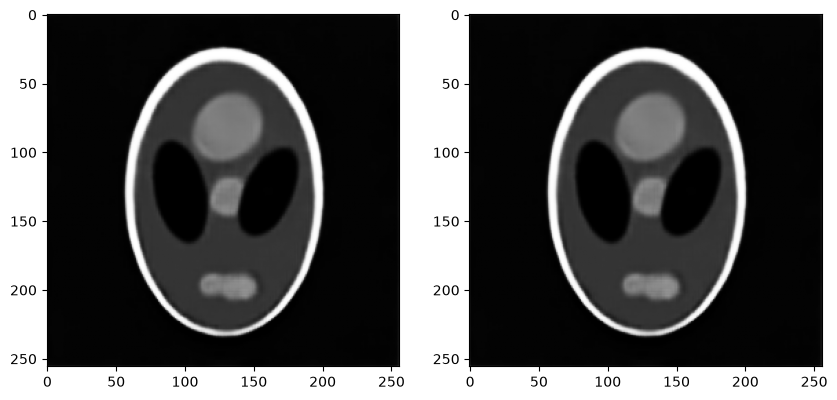

In [10]:
def extrapolate_latent_traj(z_start_extra):
    z_extra = exp_map(z_start_extra.to(config.device))[0].detach().cpu()  # (B,T,d)
    B, T, d = z_extra.shape
    if torch.isnan(z_extra).any():
        nan_batches = z_extra.isnan().any(dim=(1, 2))
        z_extra = z_extra[~nan_batches]
        print(f"Removed {nan_batches.sum().item()}/{B} z_extraectories containing NaN values.")
    if z_extra.shape[0] == 0:
        raise ValueError("No valid trajectories remaining after NaN removal.")
    t_extra = retrieve_time_from_traj(
        z_extra,
        decoder=config_finsler.decoder,
        regressor=config_finsler.regressor,
        use_pbar=False,
    )  # (B,T)
    x_extra = decode_traj(z_extra, model.decoder, config.device).cpu()
    kendall_tau_extra = kendall_tau(t_extra)
    return z_extra, x_extra, t_extra, kendall_tau_extra


idx = torch.randint(0, x_hat_geodesics.shape[0], (1,)).item()
# idx = 3
# idx = 0
idx = 9
z_traj_inter = z_traj_geodesics[idx]
x_hat_inter = x_hat_geodesics[idx]
t_traj_inter = t_traj_geodesics[idx]
kendall_tau_inter = kendall_tau_geodesics[idx]

n_traj = 50
z_start_extra = z_traj_inter[-1, :].clone().detach()
z_start_extra = z_start_extra.repeat(n_traj, 1)

print(idx)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(x_hat_inter[0, 0].cpu(), cmap="gray")
ax2.imshow(x_hat_inter[0, -1].cpu(), cmap="gray")
plt.show()

In [11]:
z_extra, x_extra, t_extra, kendall_tau_extra = extrapolate_latent_traj(z_start_extra)

In [12]:
mean_t_extra = t_extra.mean(dim=0)
std_t_extra = t_extra.std(dim=0)
end_median_idx = t_extra[:, -1].median(dim=0).indices
t_end_median = t_extra[end_median_idx, -1]
x_end_median = x_extra[end_median_idx, -1]

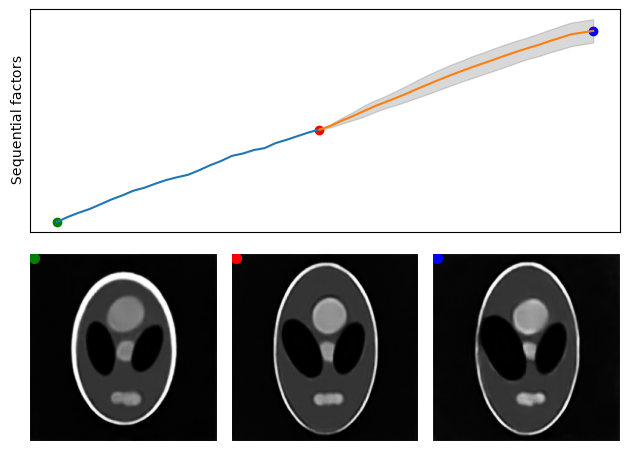

In [13]:
x_axis_idx_inter = torch.linspace(0, t_traj_inter.shape[0] - 1, t_traj_inter.shape[0]).long()
x_axis_idx_extra = torch.linspace(
    x_axis_idx_inter[-1], x_axis_idx_inter[-1] + t_extra.shape[1], t_extra.shape[1]
).long()
# plt.plot(x_axis_idx_inter, t_traj_inter)
# plt.plot(x_axis_idx_extra, t_extra.T)
fig, axes = plt.subplot_mosaic(
    [["t_pred", "t_pred", "t_pred"], ["start_img", "end_inter_img", "end_extra_img"]],
)
axes["t_pred"].plot(x_axis_idx_inter, t_traj_inter, label="interpolation")
axes["t_pred"].scatter(
    x_axis_idx_inter[0], t_traj_inter[0], color='green', label="start of interpolation"
)
# Plot the range of t_extra trajectories (mean and fill between)
axes["t_pred"].plot(x_axis_idx_extra, mean_t_extra, label="mean extrapolation")
axes["t_pred"].scatter(
    x_axis_idx_extra[0], mean_t_extra[0], color='red', label="start of extrapolation"
)
axes["t_pred"].fill_between(
    x_axis_idx_extra,
    mean_t_extra - 2 * std_t_extra,
    mean_t_extra + 2 * std_t_extra,
    color='gray',
    alpha=0.3,
    label="±2 std dev",
)
axes["t_pred"].scatter(
    x_axis_idx_extra[-1], t_end_median, color='blue', label="median end of extrapolation"
)
# for i in range(t_extra.shape[0]):
#     axes["t_pred"].plot(x_axis_idx_extra, t_extra[i], alpha=0.3)
axes["t_pred"].set_xticks([])
axes["t_pred"].set_yticks([])
axes["t_pred"].set_ylabel("Sequential factors")
axes["start_img"].imshow(x_hat_inter[0].permute(1, 2, 0), cmap="gray")
# Put a dot on the lefttop corner of the image to indicate the start of the interpolation
axes["start_img"].scatter(5, 5, color='green', s=50, label="start of interpolation")
axes["end_inter_img"].imshow(x_hat_inter[-1].permute(1, 2, 0), cmap="gray")
axes["end_inter_img"].scatter(5, 5, color='red', s=50, label="start of extrapolation")
axes["end_extra_img"].imshow(x_end_median.permute(1, 2, 0), cmap="gray")
axes["end_extra_img"].scatter(5, 5, color='blue', s=50, label="median end of extrapolation")
for ax in ["start_img", "end_inter_img", "end_extra_img"]:
    axes[ax].axis("off")

plt.tight_layout()

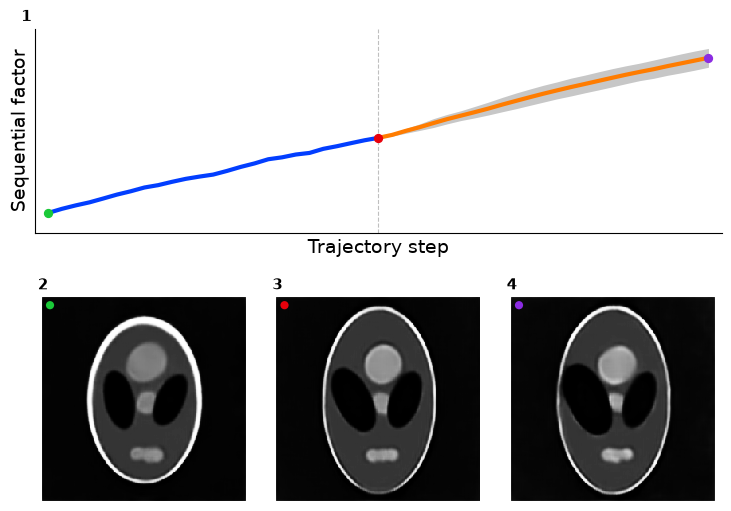

In [14]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------
def to_numpy(x):
    """Convert torch tensors (or arrays) to NumPy."""
    if hasattr(x, "detach"):
        x = x.detach().cpu()
    return np.asarray(x)


def show_image(ax, image, marker_color):
    """Display an image with a robust top-left marker."""
    image = to_numpy(image)

    # CHW -> HWC if necessary
    if image.ndim == 3 and image.shape[0] in (1, 3, 4):
        image = np.moveaxis(image, 0, -1)

    # Remove singleton channel for grayscale images
    if image.ndim == 3 and image.shape[-1] == 1:
        image = image[..., 0]

    ax.imshow(
        image,
        cmap="gray" if image.ndim == 2 else None,
        interpolation="nearest",
    )

    # Marker position independent of image resolution
    ax.scatter(
        0.04,
        0.96,
        transform=ax.transAxes,
        s=35,
        color=marker_color,
        edgecolor="none",
        zorder=10,
        clip_on=False,
    )

    ax.set_axis_off()


# ------------------------------------------------------------------
# Data preparation
# ------------------------------------------------------------------
t_inter = to_numpy(t_traj_inter).squeeze()
mean_extra = to_numpy(mean_t_extra).squeeze()
std_extra = to_numpy(std_t_extra).squeeze()
t_end = float(to_numpy(t_end_median).squeeze())

n_inter = len(t_inter)
n_extra = len(mean_extra)

# Use arange rather than linspace(...).long()
# This guarantees integer, regularly spaced indices.
x_inter = np.arange(n_inter)

# Assumes the first extrapolation point corresponds to the last
# interpolation point (shared transition point).
x_extra = x_inter[-1] + np.arange(n_extra)


# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
from seaborn import color_palette
import seaborn as sns

cmap = color_palette("bright")
COLORS = {
    "inter": cmap[0],
    "extra": cmap[1],
    "start": cmap[2],
    "transition": cmap[3],
    "end": cmap[4],
    "uncertainty": "0",
}

plt.rcParams.update(
    {
        "font.size": 14,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "axes.linewidth": 0.8,
    }
)


# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------
fig, axes = plt.subplot_mosaic(
    [
        ["t_pred", "t_pred", "t_pred"],
        ["start_img", "end_inter_img", "end_extra_img"],
    ],
    figsize=(7.2, 5.0),
    # height_ratios=[1.05, 0.85],
    height_ratios=[1.0, 1.0],
    gridspec_kw={
        "hspace": 0.08,
        "wspace": 0.07,
    },
    layout="constrained",
)


# ------------------------------------------------------------------
# Sequential factor trajectory
# ------------------------------------------------------------------
ax = axes["t_pred"]
linewidth = 3.0
marker_size = 32
ax.plot(
    x_inter,
    t_inter,
    color=COLORS["inter"],
    linewidth=linewidth,
    label="Interpolation",
)
ax.fill_between(
    x_extra,
    mean_extra - 2 * std_extra,
    mean_extra + 2 * std_extra,
    color=COLORS["uncertainty"],
    alpha=0.22,
    linewidth=0,
)
ax.plot(
    x_extra,
    mean_extra,
    color=COLORS["extra"],
    linewidth=linewidth,
)
transition_x = x_inter[-1]
ax.axvline(
    transition_x,
    color="0.75",
    linewidth=0.8,
    linestyle="--",
    zorder=0,
)

# Key points
ax.scatter(
    x_inter[0],
    t_inter[0],
    color=COLORS["start"],
    s=marker_size,
    zorder=5,
)
ax.scatter(x_extra[0], mean_extra[0], color=COLORS["transition"], s=marker_size, zorder=5)
ax.scatter(x_extra[-1], t_end, color=COLORS["end"], s=marker_size, zorder=5)


# ------------------------------------------------------------------
# Axis styling
# ------------------------------------------------------------------
ax.set_ylabel("Sequential factor")
ax.set_xlabel("Trajectory step")

# Keep the figure clean, but retain semantic temporal direction
ax.set_xticks([])
ax.set_yticks([])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(x=0.02, y=0.12)

# # Optional subtle legend
# ax.legend(
#     loc="upper left",
#     frameon=False,
#     fontsize=8,
#     ncol=3,
#     handlelength=2.0,
#     columnspacing=1.2,
# )


# ------------------------------------------------------------------
# Image panels
# ------------------------------------------------------------------
show_image(
    axes["start_img"],
    x_hat_inter[0],
    COLORS["start"],
)

show_image(
    axes["end_inter_img"],
    x_hat_inter[-1],
    COLORS["transition"],
)

show_image(
    axes["end_extra_img"],
    x_end_median,
    COLORS["end"],
)


# ------------------------------------------------------------------
# Optional panel labels
# ------------------------------------------------------------------
axes["t_pred"].text(
    -0.02,
    1.02,
    "1",
    transform=axes["t_pred"].transAxes,
    fontsize=11,
    fontweight="bold",
    va="bottom",
)

for label, key in zip(
    ["2", "3", "4"],
    ["start_img", "end_inter_img", "end_extra_img"],
):
    axes[key].text(
        -0.02,
        1.02,
        label,
        transform=axes[key].transAxes,
        fontsize=11,
        fontweight="bold",
        va="bottom",
    )
plt.savefig("./shepplogan_inter_then_extra.pdf", dpi=300, bbox_inches="tight")
plt.show()